<a href="https://colab.research.google.com/github/vicayumi/Calculo_Numerico/blob/main/atividade_CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Atividade feita por: Victoria Ayumi Kose**

Questões 5 e 6: Tabela de Iterações e Solução: 
 k     x(k)     y(k)      z(k)  Erro ||x(k) - x(k-1)||
 0 0.000000 0.000000  0.000000                     NaN
 1 0.600000 2.054545 -0.914545                2.054545
 2 0.988364 2.006711 -0.997002                0.388364
 3 1.000071 2.000279 -0.999986                0.011708
 4 1.000025 2.000004 -1.000005                0.000276
 5 1.000001 2.000000 -1.000000                0.000024
 6 1.000000 2.000000 -1.000000                0.000001

Número de iterações: 6
Solução aproximada encontrada: x = 1.00000, y = 2.00000, z = -1.00000



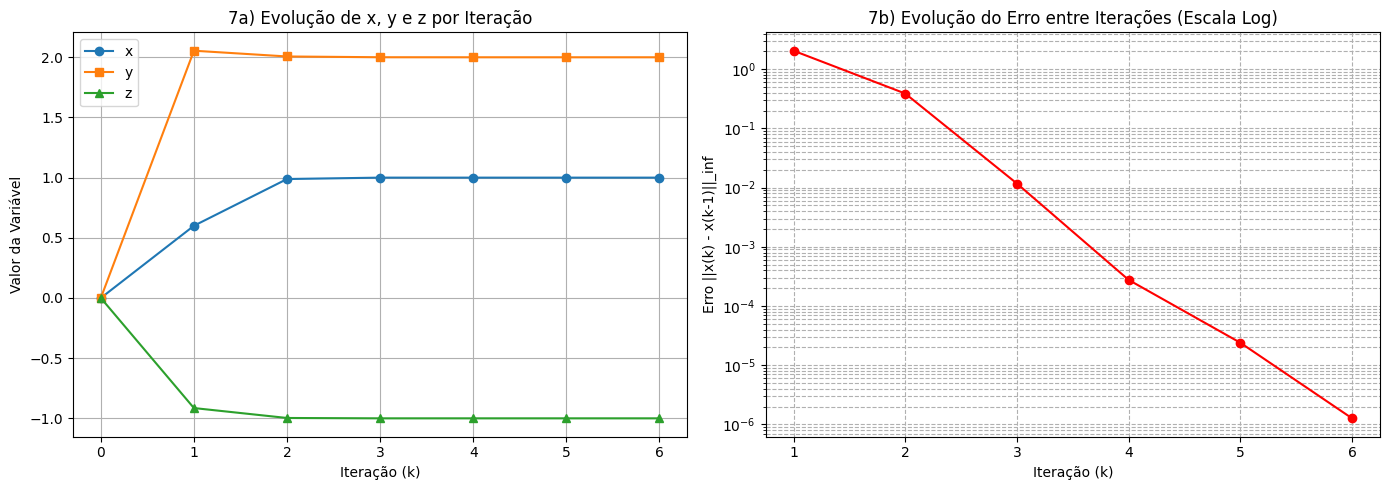

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuração de casas decimais para visualização no Pandas
pd.set_option('display.float_format', lambda x: '%.6f' % x)

# Critério de parada e número máximo de iterações
tol = 1e-5
max_iter = 50

# Inicialização (k=0)
x, y, z = 0.0, 0.0, 0.0

# Lista para armazenar o histórico (Questão 6)
historico = [{'k': 0, 'x(k)': x, 'y(k)': y, 'z(k)': z, 'Erro ||x(k) - x(k-1)||': np.nan}]

# Loop de iterações de Gauss-Seidel (Questão 5)
for k in range(1, max_iter + 1):
    x_old, y_old, z_old = x, y, z

    # Fórmulas de Gauss-Seidel
    x = (6 + y_old - 2 * z_old) / 10
    y = (22 + x + z_old) / 11
    z = (-10 - 2 * x + y) / 10

    # Cálculo do erro (norma infinito / máxima diferença absoluta)
    erro = max(abs(x - x_old), abs(y - y_old), abs(z - z_old))

    # Adiciona ao histórico
    historico.append({'k': k, 'x(k)': x, 'y(k)': y, 'z(k)': z, 'Erro ||x(k) - x(k-1)||': erro})

    # Critério de parada
    if erro < tol:
        break

# DataFrame para exibir a tabela (Questão 6)
df = pd.DataFrame(historico)
print("Questões 5 e 6: Tabela de Iterações e Solução: ")
print(df.to_string(index=False))
print(f"\nNúmero de iterações: {k}")
print(f"Solução aproximada encontrada: x = {x:.5f}, y = {y:.5f}, z = {z:.5f}\n")

# Gráficos (Questão 7)
plt.figure(figsize=(14, 5))

# a) Evolução de x, y e z
plt.subplot(1, 2, 1)
plt.plot(df['k'], df['x(k)'], marker='o', label='x')
plt.plot(df['k'], df['y(k)'], marker='s', label='y')
plt.plot(df['k'], df['z(k)'], marker='^', label='z')
plt.xlabel('Iteração (k)')
plt.ylabel('Valor da Variável')
plt.title('7a) Evolução de x, y e z por Iteração')
plt.legend()
plt.grid(True)

# b) Erro em escala logarítmica
plt.subplot(1, 2, 2)
df_erro = df.dropna() # Remove a primeira linha onde o erro é NaN
plt.semilogy(df_erro['k'], df_erro['Erro ||x(k) - x(k-1)||'], marker='o', color='red')
plt.xlabel('Iteração (k)')
plt.ylabel('Erro ||x(k) - x(k-1)||_inf')
plt.title('7b) Evolução do Erro entre Iterações (Escala Log)')
plt.grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()